In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [4]:

# Upload dataset
data = pd.read_csv("/content/balance-scale.data")

# Display the first five records
print("First five records")
print(data.head())

print("Last few records:")
print(data.tail())

x = data.iloc[:, 1:5]
y = data.iloc[:, 0]


First five records
   B  1  1.1  1.2  1.3
0  R  1    1    1    2
1  R  1    1    1    3
2  R  1    1    1    4
3  R  1    1    1    5
4  R  1    1    2    1
Last few records:
     B  1  1.1  1.2  1.3
619  L  5    5    5    1
620  L  5    5    5    2
621  L  5    5    5    3
622  L  5    5    5    4
623  B  5    5    5    5


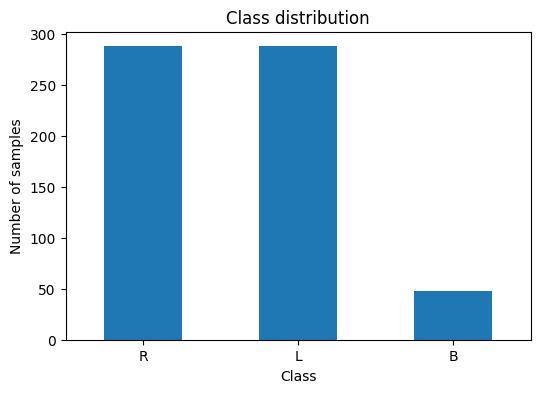

In [5]:

# Display the class distribution
class_count = y.value_counts()

plt.figure(figsize=(6, 4))
class_count.plot(kind="bar")
plt.title("Class distribution")
plt.xlabel("Class")
plt.ylabel("Number of samples")
plt.xticks(rotation=0)
plt.show()

In [6]:
# Split the dataset
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.3,
    random_state=42
)

model = DecisionTreeClassifier()
model.fit(x_train, y_train)

y_pred = model.predict(x_test)

cm = confusion_matrix(y_test, y_pred)

[[ 1  8  3]
 [13 74  0]
 [ 9  4 76]]
80.31914893617021

Classification report:
              precision    recall  f1-score   support

           B       0.04      0.08      0.06        12
           L       0.86      0.85      0.86        87
           R       0.96      0.85      0.90        89

    accuracy                           0.80       188
   macro avg       0.62      0.60      0.61       188
weighted avg       0.86      0.80      0.83       188



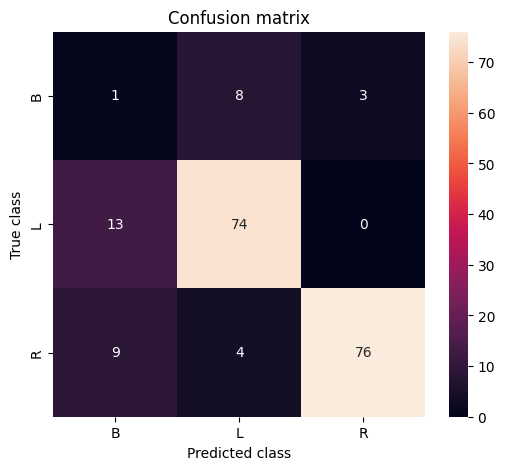

In [7]:
# Accuracy, precision, recall, F1-score
print(cm)

accuracy = accuracy_score(y_test, y_pred)
print(accuracy * 100)

print("\nClassification report:")
print(classification_report(y_test, y_pred))

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title("Confusion matrix")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.show()